# Chapter 4 · ARIMA and SARIMA

*Book 21 · Time Series · Shelf V*

**Builds on:** [Chapter 3](03-stationarity-and-autocorrelation.ipynb) -- stationarity, ACF and
differencing.
**You will:** simulate AR and MA processes and recover their parameters, fit a seasonal ARIMA
to daily electricity, check its residuals, and forecast four weeks with prediction intervals.

ARIMA(p, d, q) is the workhorse of classical forecasting: difference $d$ times to get a
stationary series, then model it as a combination of its own past values (**AR**, order $p$)
and past shocks (**MA**, order $q$). SARIMA adds the same three at the seasonal lag.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.statespace.sarimax import SARIMAX

from ds_toolbox import baselines, evaluation, io, viz

viz.use_style()
warnings.filterwarnings("ignore", category=UserWarning)   # convergence chatter from statsmodels

## AR and MA, simulated

- AR(1): $y_t = \phi\, y_{t-1} + \varepsilon_t$ -- today is a fraction of yesterday plus a shock.
  Its **PACF** cuts off after lag 1; its ACF decays.
- MA(1): $y_t = \varepsilon_t + \theta\, \varepsilon_{t-1}$ -- today carries part of yesterday's
  shock. Its **ACF** cuts off after lag 1; its PACF decays.

That mirror image is how orders were chosen before information criteria made it automatic.

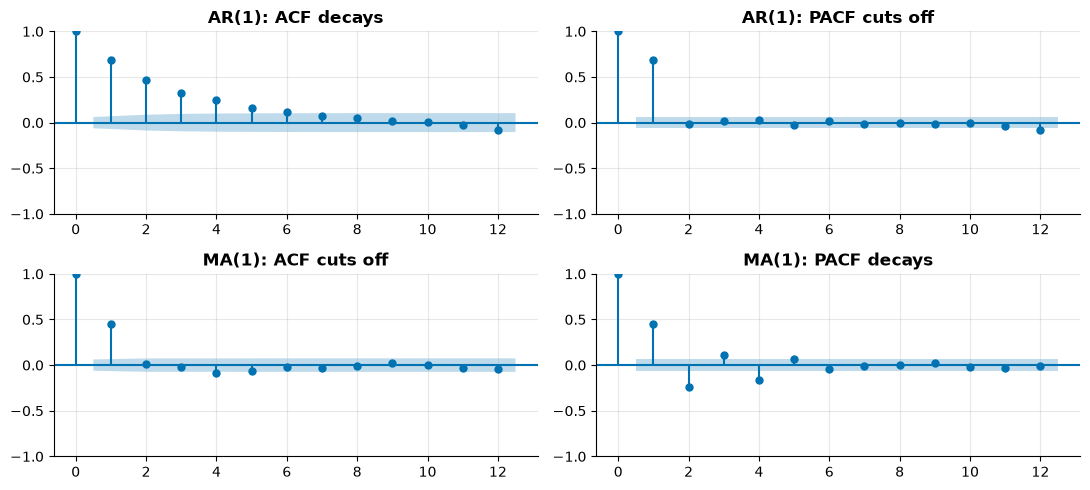

In [2]:
np.random.seed(4)
ar1 = ArmaProcess(ar=[1, -0.7], ma=[1]).generate_sample(1000)
ma1 = ArmaProcess(ar=[1], ma=[1, 0.6]).generate_sample(1000)
fig, axes = plt.subplots(2, 2, figsize=(11, 5))
plot_acf(ar1, lags=12, ax=axes[0, 0], title="AR(1): ACF decays")
plot_pacf(ar1, lags=12, ax=axes[0, 1], title="AR(1): PACF cuts off", method="ywm")
plot_acf(ma1, lags=12, ax=axes[1, 0], title="MA(1): ACF cuts off")
plot_pacf(ma1, lags=12, ax=axes[1, 1], title="MA(1): PACF decays", method="ywm")
fig.tight_layout()

In [3]:
print("AR(1) phi  true 0.70  estimated", round(ARIMA(ar1, order=(1, 0, 0)).fit().arparams[0], 3))
print("MA(1) theta true 0.60  estimated", round(ARIMA(ma1, order=(0, 0, 1)).fit().maparams[0], 3))

AR(1) phi  true 0.70  estimated 0.687
MA(1) theta true 0.60  estimated 0.628


## A seasonal model for daily electricity

Daily mean load has a weekly season (chapter 2) that one seasonal difference at lag 7 removes
(chapter 3). So: SARIMA$(1,0,1)\times(1,1,1)_7$ -- one seasonal difference, AR and MA terms at
lag 1 and at lag 7. We fit on two years and hold out the last 28 days.

In [4]:
raw = io.load_sample("ewz_zurich_hourly.csv.gz")
daily = (raw.assign(t=pd.to_datetime(raw["hour_utc"], utc=True)).set_index("t")["total_mwh"]
         .tz_convert("Europe/Zurich").resample("D").mean().tz_localize(None).asfreq("D"))
daily = daily.iloc[1:-1]                       # drop the two partial days at the ends
train, test = daily.iloc[-(2 * 365 + 28):-28], daily.iloc[-28:]

model = SARIMAX(train, order=(1, 0, 1), seasonal_order=(1, 1, 1, 7)).fit(disp=False)
print(model.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8884      0.017     52.295      0.000       0.855       0.922
ma.L1         -0.0565      0.030     -1.858      0.063      -0.116       0.003
ar.S.L7        0.1272      0.033      3.844      0.000       0.062       0.192
ma.S.L7       -0.9999      2.285     -0.438      0.662      -5.478       3.478
sigma2        94.3574    214.411      0.440      0.660    -325.881     514.595


## Are the residuals white noise?

If the model captured the structure, what it leaves should be unpredictable. The Ljung-Box test's
null is "no autocorrelation up to lag k": a large p-value is what we want.

,lb_stat,lb_pvalue
7,16.926,0.018
14,37.158,0.001


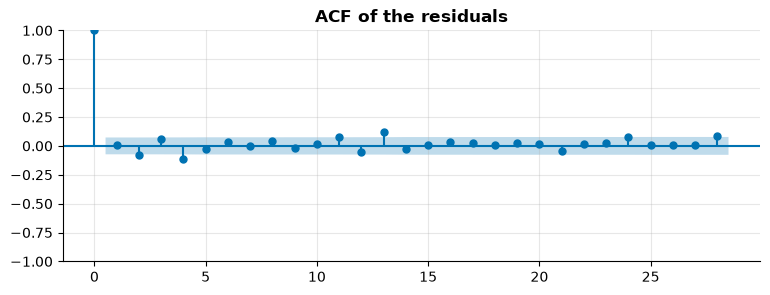

In [5]:
resid = model.resid.iloc[8:]                   # the first values absorb the differencing
lb = acorr_ljungbox(resid, lags=[7, 14], return_df=True)
fig, ax = plt.subplots(figsize=(9, 3))
plot_acf(resid, lags=28, ax=ax, title="ACF of the residuals")
lb.round(3)

Some autocorrelation is left: holidays and weather are not in a model that only sees the series
itself. That is the opening for chapter 6.

## Forecasting with intervals

A forecast is a distribution, not a number. SARIMA gives a prediction interval that widens with
the horizon. Next to it, the seasonal-naive baseline: "the same weekday last week".

MAE  SARIMA 10.9 MW · seasonal naive 22.4 MW
actual days inside the 95 % interval: 100%


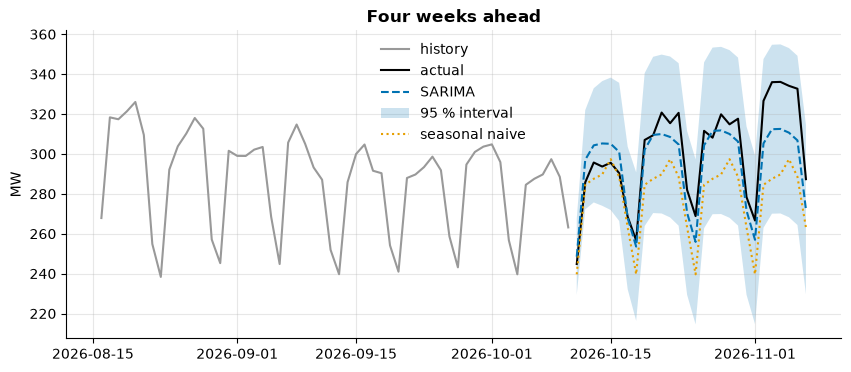

In [6]:
fc = model.get_forecast(steps=len(test))
mean, ci = fc.predicted_mean, fc.conf_int(alpha=0.05)
naive = pd.Series(baselines.seasonal_naive(7)(train, len(test)), index=test.index)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(train.iloc[-56:], color="0.6", label="history")
ax.plot(test, color="black", label="actual")
ax.plot(mean, ls="--", label="SARIMA")
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=0.2, label="95 % interval")
ax.plot(naive, ls=":", label="seasonal naive")
ax.set(ylabel="MW", title="Four weeks ahead")
ax.legend()

inside = ((test >= ci.iloc[:, 0]) & (test <= ci.iloc[:, 1])).mean()
print(f"MAE  SARIMA {evaluation.mae(test, mean):.1f} MW · seasonal naive {evaluation.mae(test, naive):.1f} MW")
print(f"actual days inside the 95 % interval: {inside:.0%}")

All 28 days inside a 95 % interval is more than 95 %: the interval is wide here, partly because
the seasonal MA term sits at the edge of invertibility (about -1), which the large standard
errors in the table above show. And one four-week window is one draw -- whether SARIMA is
*reliably* better is a question for many windows: chapter 5.

## What to remember

- AR uses past values, MA past shocks; the ACF and PACF tell them apart.
- Seasonal ARIMA = ARIMA at lag 1 plus ARIMA at the seasonal lag.
- Check residuals with Ljung-Box, and report intervals, not only the mean.

## Exercises

1. Fit `(2,0,1)x(0,1,1,7)` and compare the AIC with the model above.
2. Shorten the training window to six months. What happens to the interval width?
3. Count how often the actual value falls inside an *80 %* interval over the 28 days.

**Next:** [Chapter 5 · Backtesting](05-backtesting.ipynb)